Inicializo las librerias que voy a usar

In [50]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

DECLARO LAS FUNCIONES QUE VOY A USAR

Funcion para pasar de RGB a  YIQ

In [51]:
def RGBaYIQ(imagen):
       M = np.array([[0.299, 0.587, 0.114],
                  [0.596, -0.275, -0.321],
                  [0.212, -0.523, 0.311]])

       R=imagen[:,:,2]
       G=imagen[:,:,1]
       B=imagen[:,:,0]

       alto,ancho=R.shape # obtengo las dimensiones de la matriz

       # Reorganizar la imagen: (alto*ancho, 3)
       rgb = np.stack([R, G, B],axis=-1).reshape(-1, 3) #une secuencias de matrices, 3 columnas y las filas las determina numpy por eso el  -1
       yiq = np.dot(rgb, M.T)

       # Volver a la forma original
       yiq = yiq.reshape(alto, ancho, 3)

       Y=yiq[:,:,0]
       I=yiq[:,:,1]
       Q=yiq[:,:,2]

       return Y,I,Q

Funcion para pasar de YIQ a RGB

In [52]:
def YIQaRGB(Y,I,Q):
          matriz=np.array([[1, 0.9663, 0.6210],
                          [1, -0.2721, -0.6474],
                          [1, -1.1070, 1.7046]])

          alto, ancho = Y.shape
          yiq = np.stack([Y, I, Q], axis=-1).reshape(-1, 3)# Reorganizar en (alto*ancho, 3)
          rgb = np.dot(yiq, matriz.T)
          rgb = rgb.reshape(alto, ancho, 3)
          rgb = np.clip(rgb, 0, 1) # limita los valores entre 0 y 1

          return (rgb*255).astype(np.uint8)

Funcion para normalizar una imagen

In [53]:
def normalizarImagen(imagen):
  return imagen/255

Funcion para calcular la Transformada de fourier de modulo y fase

In [54]:
def fft_imagen(imagen):
    x = np.fft.fft2(imagen)
    x = np.fft.fftshift(x)
    modulo = np.abs(x)
    fase = np.angle(x)
    modulo_log = np.log1p(modulo)
    return modulo,fase,modulo_log


In [55]:
def ifft_imagen(modulo, fase):
    #reconstruir TF
    transformada_reconstruida=modulo*np.exp(1j*fase)
    #desentrar
    f_ishift=np.fft.ifftshift(transformada_reconstruida)
    # Reconstruir imagen aplicando la inversa
    imagen_reconstruida = np.fft.ifft2(f_ishift)
    imagen_reconstruida = np.abs(imagen_reconstruida)

    return imagen_reconstruida


In [56]:
def mostrar_imagen(imagen,colormap,titulo):
  plt.imshow(imagen, cmap=colormap)
  plt.axis('off')
  plt.title(titulo)

In [57]:
#def inversa_log1p_modulo(modulo_log):
#    return np.expm1(modulo_log)

def inversa_log1p_modulo(modulo_log, max_log=9.0):
    """
    Invierte la escala logarítmica del módulo guardado como imagen.
    """
    # Asegurar rango [0,1]
    modulo_norm = modulo_log.astype(np.float64)
    if modulo_norm.max() > 1:
        modulo_norm /= 255.0

    # Reescalar y aplicar exponencial inversa
    modulo_log = modulo_norm * max_log
    modulo_lineal = np.expm1(modulo_log)

    # Normalizar resultado
    modulo_lineal /= np.max(modulo_lineal)
    return modulo_lineal

APLICO LAS FUNCIONES CREADAS

Cargar imagen y normalizo la imagen

In [58]:
imagen = cv2.imread("circulo.jpg")
imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
imagen = normalizarImagen(imagen)

Descompongo la imagen en YIQ, calculo la transformada de Fourier de modulo y fase , y determino las filas y columnas del ploteo

In [59]:
y,i,q=RGBaYIQ(imagen)
modulo,fase,modulo_log=fft_imagen(y) #El modulo me lo da normalizado
filas=1
columnas=3

Mostrar Imagen
https://matplotlib.org/stable/gallery/color/colormap_reference.*html*.
Voy a usar otro "cmap" aparte de "gray" para visualizar el modulo y la fase solo de forma estetica. Si necesitara editar el modulo para filtrar algo  lo trabajo en  "cmap="gray""

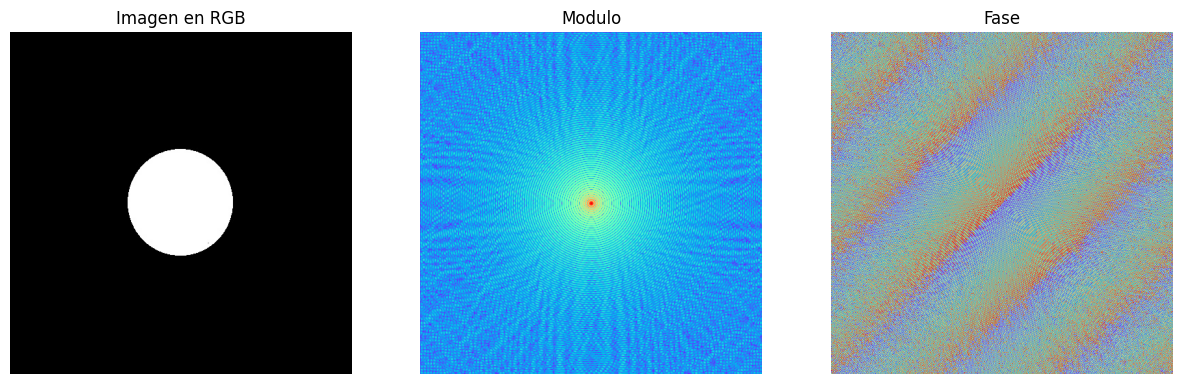

In [60]:
plt.figure(figsize=(15,15))
plt.subplot(filas,columnas,1)
mostrar_imagen(imagen,"gray","Imagen en RGB")

plt.subplot(filas,columnas,2)
mostrar_imagen(modulo_log,"rainbow","Modulo")

plt.subplot(filas,columnas,3)
mostrar_imagen(fase,"rainbow","Fase")


plt.show()

Ahora teniendo el modulo y fase calculo la antitransformada

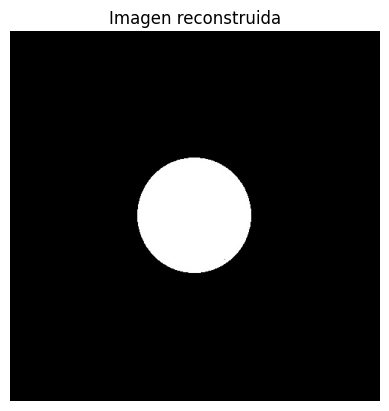

In [61]:
img_reconstruida=ifft_imagen(modulo,fase)
mostrar_imagen(img_reconstruida,"gray","Imagen reconstruida")

INTENTAR MODIFICAR UNA IMAGEN ELIMINANDO PARTE DELPARTE DEL MODULO DE LA TRANSFOMADA DE FOURIER

Tengo una imagen que se tomo cruzando un puente, al tomar la foto se tomo parte de la barandilla de color rojo. la idea es eliminar esta barandilla. Primero se calculo la TF de la imagen real y se plotea junto con la imagen

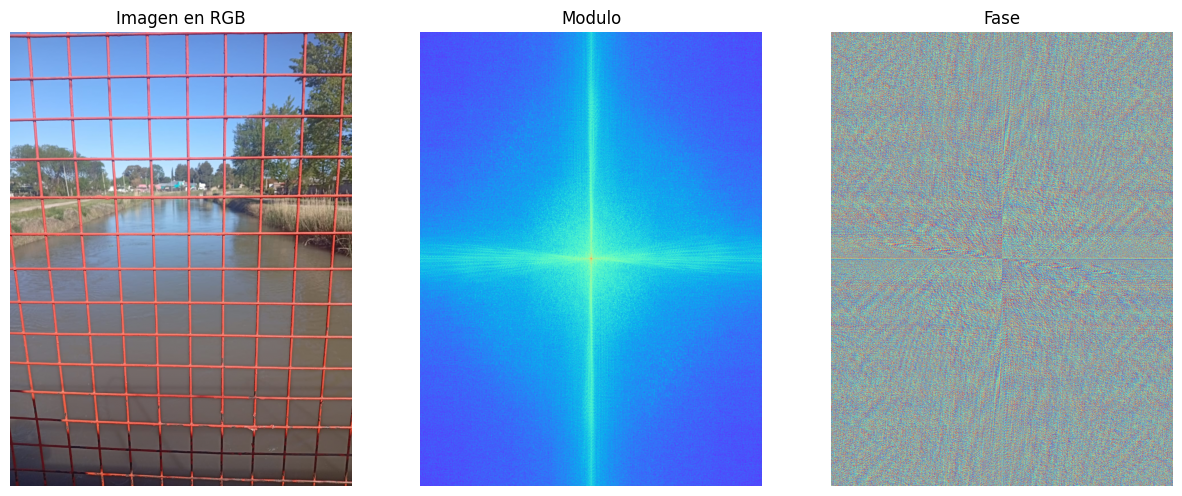

In [62]:
imagen2=cv2.imread("luro.jpg")
imagen2=cv2.cvtColor(imagen2,cv2.COLOR_BGR2RGB)
imagen2=normalizarImagen(imagen2)

y2,i2,q2=RGBaYIQ(imagen2)
modulo2,fase2,modulo_log2=fft_imagen(y2)

plt.figure(figsize=(15,15))

plt.subplot(filas,columnas,1)
mostrar_imagen(imagen2,"gray","Imagen en RGB")

plt.subplot(filas,columnas,2)
mostrar_imagen(modulo_log2,"rainbow","Modulo")

plt.subplot(filas,columnas,3)
mostrar_imagen(fase2,"rainbow","Fase")
plt.show()


Se descarga la imagen del modulo y fase en imagenes separadaas en color gris porque es mucho mas facil modificar el modulo en esta escala en paint

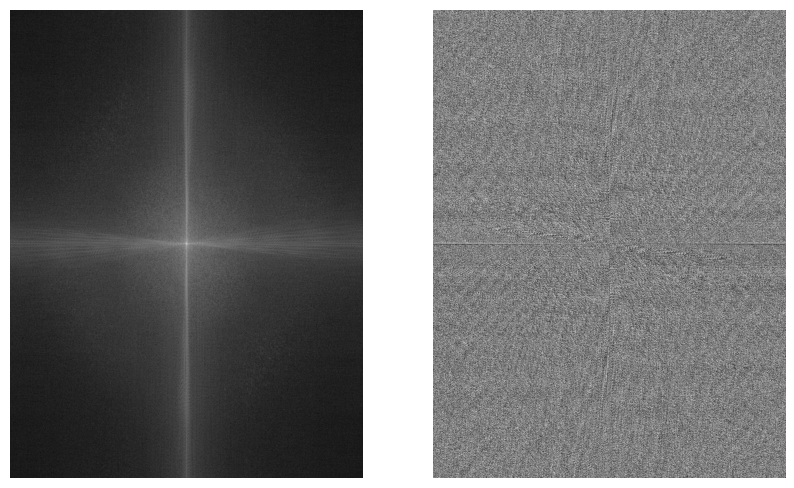

In [63]:
plt.figure(figsize=(10,10))

plt.subplot(1,2,1)
mostrar_imagen(modulo_log2,"gray","")
plt.subplot(1,2,2)
mostrar_imagen(fase2,"gray","")

Se dibujo en paint una rejilla para ver como se distribuye aproximadamentees el espectro de frecuencia del modulo y  para luego ver que eliminar en el espectro de la imagen real.

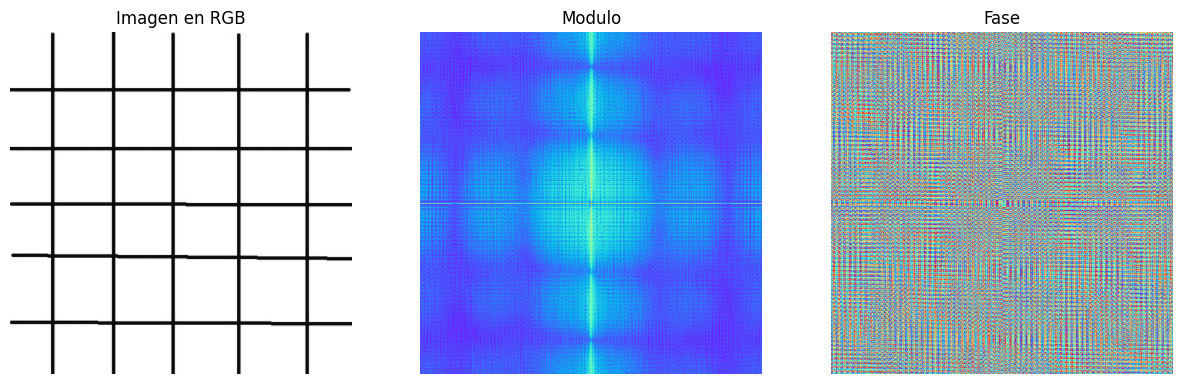

In [64]:
imagen3=cv2.imread("rejilla_roja.jpg")
imagen3=cv2.cvtColor(imagen3,cv2.COLOR_BGR2RGB)
imagen3=normalizarImagen(imagen3)

y3,i3,q3=RGBaYIQ(imagen3)
modulo3,fase3,modulo_log3=fft_imagen(y3)

plt.figure(figsize=(15,15))
plt.subplot(filas,columnas,1)
mostrar_imagen(y3,"gray","Imagen en RGB")

plt.subplot(filas,columnas,2)
mostrar_imagen(modulo_log3,"rainbow","Modulo")

plt.subplot(filas,columnas,3)
mostrar_imagen(fase3,"rainbow","Fase")

#plt.show()


En estas lineas descargo la imagenes para modificar

IMPORTANTE: Originalmente ploteando la imagen  y la descargaba como “Guardar imagen como…” pero encontre un problema, lo que hacia es descargar una foto grafica del modulo y al parecer no guardaba los datos reales (la reconstruccion era una imagen toda negra). Pero guardandolo de la siguiente forma (el codigo) si me permitia reconstuirla ¿por que? ni idea jaja

https://www.geeksforgeeks.org/python/save-plot-to-numpy-array-using-matplotlib/?utm_source=chatgpt.com

In [65]:
modulo_log_norm=modulo_log2/np.max(modulo_log2)  # Guardar módulo en escala logarítmica
cv2.imwrite("modulo_para_paint.png",(modulo_log_norm*255).astype(np.uint8))
fase_norm = (fase2 + np.pi) / (2 * np.pi)        # Guardar fase mapeada de [-pi, pi] a [0,255]
cv2.imwrite("fase_para_paint.png",(fase_norm*255).astype(np.uint8))


True

En esta seccion muestro la imagenes del modulo original con la del modulo modificado

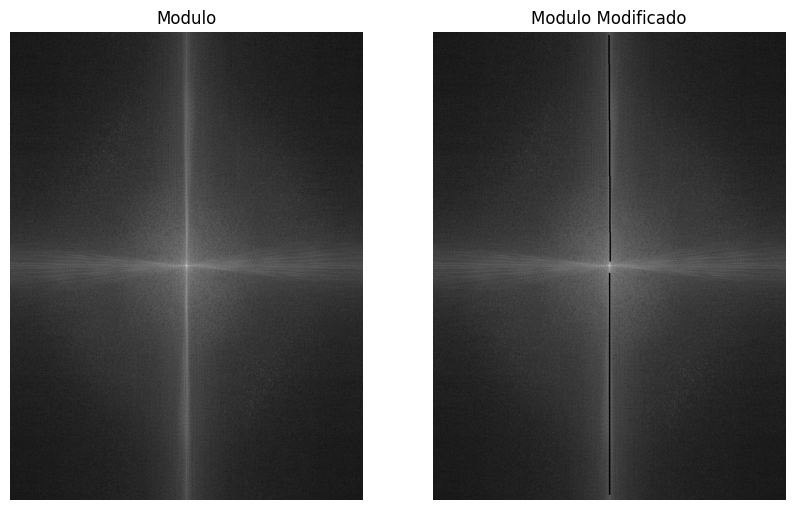

In [66]:
img_modificada=cv2.imread("modulo_para_paint_modificada.png")
img_modificada=cv2.cvtColor(img_modificada,cv2.COLOR_BGR2RGB)
img_modificada=normalizarImagen(img_modificada)
plt.figure(figsize=(10,10))

plt.subplot(1,2,1)
mostrar_imagen(modulo_log2,"gray","Modulo")

plt.subplot(1,2,2)
mostrar_imagen(img_modificada,"gray","Modulo Modificado")



Reconstruyo la imagen

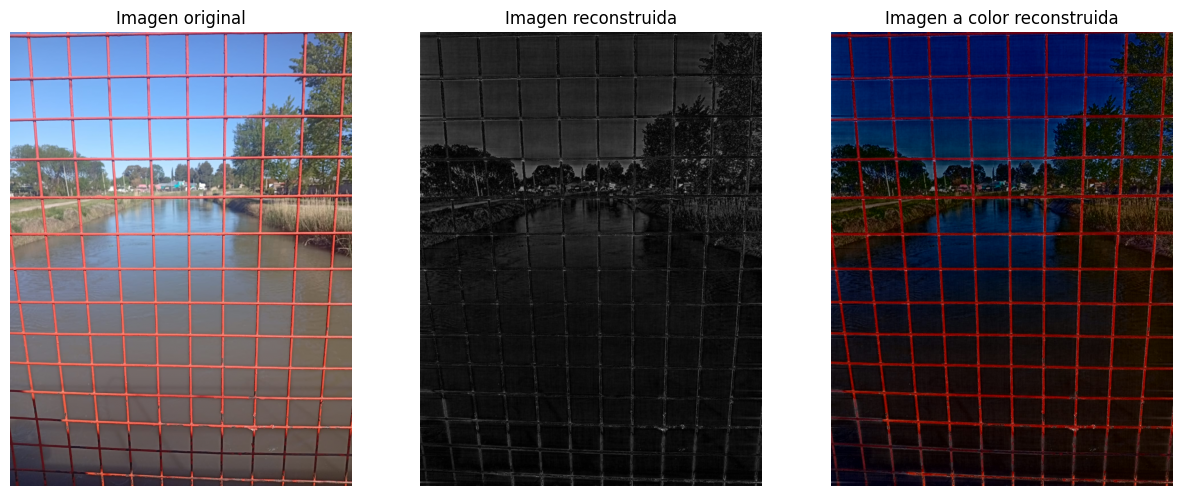

In [70]:
img_mod=cv2.imread("modulo_para_paint_modificada.png", cv2.IMREAD_GRAYSCALE).astype(np.float64)
img_fase=cv2.imread("fase_para_paint.png", cv2.IMREAD_GRAYSCALE).astype(np.float64)

img_mod=normalizarImagen(img_mod)
img_fase=normalizarImagen(img_fase)

# Reconstruir
modulo=np.expm1(img_mod*np.max(modulo_log))
modulo=modulo/np.max(modulo)

fase = (img_fase*2*np.pi)-np.pi

img_reconstruida=ifft_imagen(modulo, fase)
img_reconstruida= img_reconstruida/np.max(img_reconstruida) #normalizar la imagen reconstruida

img_color=YIQaRGB(img_reconstruida,i2,q2)
img_color=cv2.cvtColor(img_color,cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,15))

plt.subplot(1,3,1)
mostrar_imagen(imagen2,"gray","Imagen original")

plt.subplot(1,3,2)
mostrar_imagen(img_reconstruida, "gray", "Imagen reconstruida")

plt.subplot(1,3,3)
mostrar_imagen(img_color, "gray", "Imagen a color reconstruida")




Conclusión: Aunque se puede observar el efecto de la modificación del módulo, la aproximación mediante una cuadrícula roja no funcionó. Sin embargo, existen formas más eficientes de lograrlo.
Una posibilidad es que, dado que en la imagen real lo único rojo es la rejilla, podría aislarse esta región clampeando a blanco todo el resto, realizar la transformada de Fourier (TF), luego aplicar la TF a la imagen real y por ultimo calcular la diferencia entre ambas para reconstruir la imagen.